# Phase 10 — Cross-Validation Deep-Dive

**Objective:** Go beyond simple mean CV scores to understand each model's learning dynamics, bias-variance trade-off, probability calibration, and the effect of the decision threshold.

| Analysis | Question answered |
|---|---|
| **Learning Curves** | Does adding more data still improve the model? |
| **Bias-Variance Gap** | Is each model underfitting or overfitting? |
| **Fold Distributions** | How stable are metrics across folds? |
| **Calibration** | Are predicted probabilities well-calibrated? |
| **Threshold Sensitivity** | What decision threshold maximises F1? |

**Rules enforced:**
- ✅ All analysis on `train.csv` + `cv_folds.json` only — `test.csv` untouched
- ✅ Each fold fits fresh pipeline clones — no state leakage
- ✅ `random_state=42` everywhere

## 10.0  Setup & Imports

In [1]:
import sys, json, time, warnings, pathlib
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
warnings.filterwarnings('ignore')

def _find_root(start):
    for p in [start] + list(start.parents):
        if (p / 'params.yaml').exists():
            return p
    return start

import os
PROJECT_ROOT = _find_root(pathlib.Path.cwd())
os.chdir(PROJECT_ROOT)
if str(PROJECT_ROOT) not in sys.path:
    sys.path.insert(0, str(PROJECT_ROOT))

from sklearn.calibration import calibration_curve
from sklearn.dummy import DummyClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import f1_score, precision_score, recall_score, roc_auc_score
from xgboost import XGBClassifier

from src.data.preprocessing import build_full_pipeline
from src.utils.config import PARAMS

RANDOM_STATE = PARAMS['random_state']
TARGET       = PARAMS['dataset']['target_column']
GAP_THRESH   = PARAMS['diagnosis']['gap_threshold']
LOW_F1       = PARAMS['diagnosis']['low_performance_f1']

MODEL_COLORS = {
    'DummyClassifier':    '#6B7280',
    'LogisticRegression': '#3B82F6',
    'RandomForest':       '#10B981',
    'XGBoost':            '#F59E0B',
}
MODEL_NAMES = list(MODEL_COLORS.keys())
print(f'Project root : {PROJECT_ROOT}')
print(f'Random state : {RANDOM_STATE}')
print(f'Gap threshold: {GAP_THRESH}')

Project root : C:\Users\Abhishek\OneDrive\Pictures\Desktop\ChurnOps
Random state : 42
Gap threshold: 0.08


## 10.1  Load Data & CV Folds

In [2]:
df_train = pd.read_csv('data/processed/train.csv')
with open('data/processed/cv_folds.json') as f:
    cv_folds = json.load(f)

X = df_train.drop(columns=[TARGET])
y = df_train[TARGET]
FOLD_NAMES = sorted(cv_folds.keys())

print(f'Training set : {len(df_train):,} rows x {df_train.shape[1]} cols')
print(f'CV folds     : {len(FOLD_NAMES)}')
print(f'Churn rate   : {y.mean():.3f}  ({y.sum()} positives)')

Training set : 5,634 rows x 20 cols
CV folds     : 5
Churn rate   : 0.265  (1495 positives)


## 10.2  Helper Functions

In [3]:
def _compute_spw(y_s):
    neg = (y_s == 0).sum()
    pos = (y_s == 1).sum()
    return float(neg / pos) if pos > 0 else 1.0

def build_pipelines(y_ref):
    spw = _compute_spw(y_ref)
    return {
        'DummyClassifier': build_full_pipeline(
            estimator=DummyClassifier(strategy='stratified', random_state=RANDOM_STATE),
            scale_numeric=True),
        'LogisticRegression': build_full_pipeline(
            estimator=LogisticRegression(class_weight='balanced', max_iter=1000,
                solver='lbfgs', random_state=RANDOM_STATE),
            scale_numeric=True),
        'RandomForest': build_full_pipeline(
            estimator=RandomForestClassifier(n_estimators=200, class_weight='balanced',
                random_state=RANDOM_STATE, n_jobs=-1),
            scale_numeric=False),
        'XGBoost': build_full_pipeline(
            estimator=XGBClassifier(n_estimators=200, scale_pos_weight=spw,
                eval_metric='logloss', random_state=RANDOM_STATE,
                n_jobs=-1, verbosity=0),
            scale_numeric=False),
    }

def get_splits():
    splits = []
    for fn in FOLD_NAMES:
        fd = cv_folds[fn]
        splits.append((
            X.iloc[fd['train_indices']].reset_index(drop=True),
            y.iloc[fd['train_indices']].reset_index(drop=True),
            X.iloc[fd['val_indices']].reset_index(drop=True),
            y.iloc[fd['val_indices']].reset_index(drop=True),
        ))
    return splits

print('Helper functions ready.')

Helper functions ready.


## 10.3  Bias-Variance Gap Analysis

> Fits each model on the **full** training fold and measures the gap between train-F1 and val-F1.  
> **Gap > 0.08** → overfitting. **Val F1 < 0.50** → underfitting.

In [4]:
bv_results = {}
for name in MODEL_NAMES:
    train_f1s, val_f1s = [], []
    for X_tr, y_tr, X_val, y_val in get_splits():
        pipes = build_pipelines(y_tr)
        pipe  = pipes[name]
        if name == 'XGBoost':
            pipe.named_steps['model'].set_params(scale_pos_weight=_compute_spw(y_tr))
        pipe.fit(X_tr, y_tr)
        train_f1s.append(f1_score(y_tr,  pipe.predict(X_tr),  zero_division=0))
        val_f1s.append(  f1_score(y_val, pipe.predict(X_val), zero_division=0))

    mt = float(np.mean(train_f1s))
    mv = float(np.mean(val_f1s))
    gap = mt - mv
    diag = 'underfitting' if mv < LOW_F1 else ('overfitting' if gap > GAP_THRESH else 'good_fit')
    bv_results[name] = {'mean_train_f1': round(mt,4), 'mean_val_f1': round(mv,4),
                        'gap': round(gap,4), 'diagnosis': diag}
    print(f'{name:<24}  train={mt:.4f}  val={mv:.4f}  gap={gap:.4f}  -> {diag}')

print('\nDone.')

DummyClassifier           train=0.2544  val=0.2762  gap=-0.0218  -> underfitting


LogisticRegression        train=0.6326  val=0.6258  gap=0.0067  -> good_fit


RandomForest              train=0.9958  val=0.5465  gap=0.4494  -> overfitting


XGBoost                   train=0.9568  val=0.5780  gap=0.3788  -> overfitting

Done.


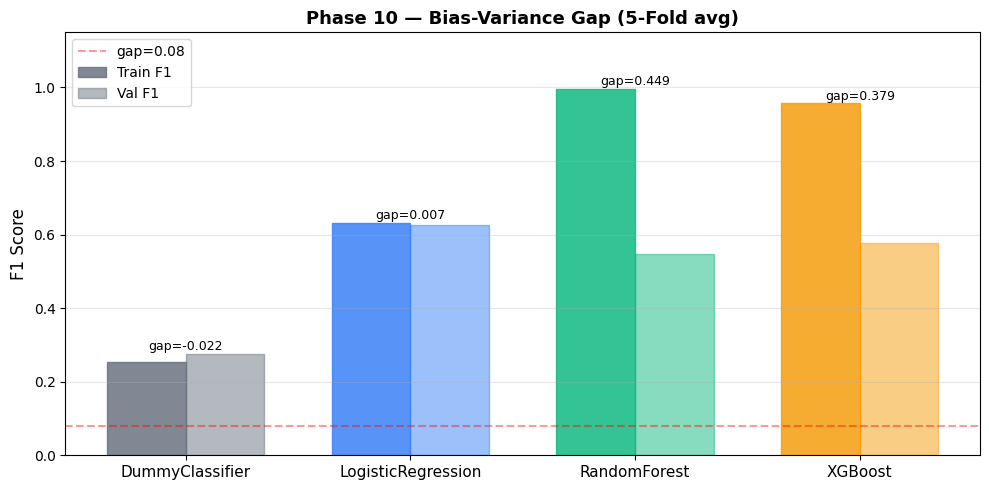

Saved: reports/cv_bias_variance_bar.png


In [5]:
# Bar chart: Train vs Val F1 with gap shading
names = list(bv_results.keys())
x = np.arange(len(names))
w = 0.35
fig, ax = plt.subplots(figsize=(10, 5))
bars_tr  = ax.bar(x - w/2, [bv_results[n]['mean_train_f1'] for n in names],
                  w, label='Train F1', alpha=0.85)
bars_val = ax.bar(x + w/2, [bv_results[n]['mean_val_f1'] for n in names],
                  w, label='Val F1',   alpha=0.85)
for i, (bar_t, bar_v, name) in enumerate(zip(bars_tr, bars_val, names)):
    color = MODEL_COLORS.get(name, 'gray')
    bar_t.set_color(color); bar_v.set_color(color); bar_v.set_alpha(0.5)
    gap = bv_results[name]['gap']
    ax.text(x[i], max(bar_t.get_height(), bar_v.get_height()) + 0.01,
            f'gap={gap:.3f}', ha='center', fontsize=9, color='black')
ax.set_xticks(x)
ax.set_xticklabels(names, fontsize=11)
ax.set_ylabel('F1 Score', fontsize=12)
ax.set_ylim(0, 1.15)
ax.axhline(GAP_THRESH + 0, color='red', ls='--', alpha=0.4, label=f'gap={GAP_THRESH}')
ax.set_title('Phase 10 — Bias-Variance Gap (5-Fold avg)', fontsize=13, fontweight='bold')
ax.legend(fontsize=10)
ax.grid(axis='y', alpha=0.3)
plt.tight_layout()
plt.savefig('reports/cv_bias_variance_bar.png', dpi=150, bbox_inches='tight')
plt.show()
print('Saved: reports/cv_bias_variance_bar.png')

## 10.4  Learning Curves

> Trains each model on **growing subsets** of each fold's training data.  
> Shaded area between train and val F1 shows the variance gap.

In [6]:
TRAIN_FRACS = [0.10, 0.25, 0.40, 0.60, 0.80, 1.00]
lc_data = {}

for name in MODEL_NAMES:
    print(f'Learning curve: {name}')
    frac_tr  = {f: [] for f in TRAIN_FRACS}
    frac_val = {f: [] for f in TRAIN_FRACS}

    for X_tr, y_tr, X_val, y_val in get_splits():
        n_total = len(X_tr)
        for frac in TRAIN_FRACS:
            n = max(50, int(n_total * frac))
            Xs, ys = X_tr.iloc[:n], y_tr.iloc[:n]
            sub_pipe = build_pipelines(ys)[name]
            if name == 'XGBoost':
                sub_pipe.named_steps['model'].set_params(scale_pos_weight=_compute_spw(ys))
            sub_pipe.fit(Xs, ys)
            frac_tr[frac].append( f1_score(ys,    sub_pipe.predict(Xs),    zero_division=0))
            frac_val[frac].append(f1_score(y_val, sub_pipe.predict(X_val), zero_division=0))

    n_total_avg = len(df_train) * 4 // 5  # approx fold train size
    lc_data[name] = {
        'sizes':    [max(50, int(n_total_avg * f)) for f in TRAIN_FRACS],
        'train_f1': [np.mean(frac_tr[f])  for f in TRAIN_FRACS],
        'val_f1':   [np.mean(frac_val[f]) for f in TRAIN_FRACS],
    }
print('Done.')

Learning curve: DummyClassifier


Learning curve: LogisticRegression


Learning curve: RandomForest


Learning curve: XGBoost


Done.


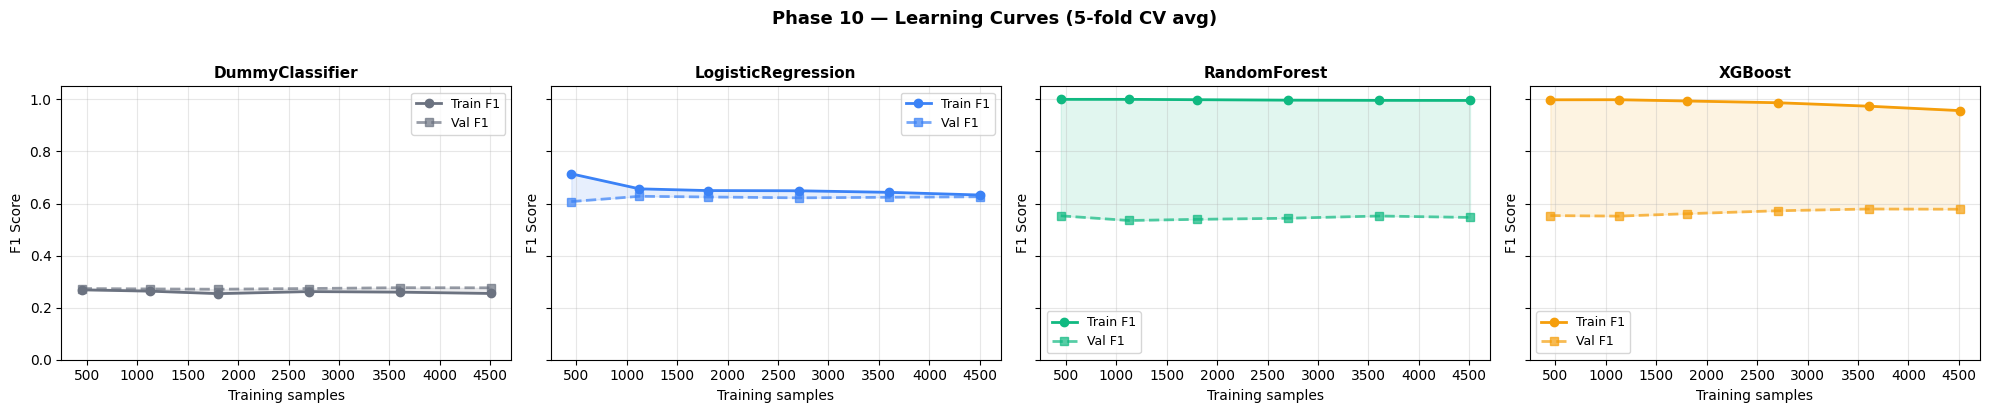

Saved: reports/cv_learning_curves.png


In [7]:
fig, axes = plt.subplots(1, 4, figsize=(20, 4), sharey=True)
for ax, name in zip(axes, MODEL_NAMES):
    d = lc_data[name]
    color = MODEL_COLORS[name]
    ax.plot(d['sizes'], d['train_f1'], 'o-',  color=color, lw=2,   label='Train F1')
    ax.plot(d['sizes'], d['val_f1'],   's--', color=color, lw=2, alpha=0.7, label='Val F1')
    ax.fill_between(d['sizes'], d['train_f1'], d['val_f1'], alpha=0.12, color=color)
    ax.set_title(name, fontsize=11, fontweight='bold')
    ax.set_xlabel('Training samples', fontsize=10)
    ax.set_ylabel('F1 Score', fontsize=10)
    ax.legend(fontsize=9)
    ax.grid(alpha=0.3)
    ax.set_ylim(0, 1.05)
plt.suptitle('Phase 10 — Learning Curves (5-fold CV avg)',
             fontsize=13, fontweight='bold', y=1.02)
plt.tight_layout()
plt.savefig('reports/cv_learning_curves.png', dpi=150, bbox_inches='tight')
plt.show()
print('Saved: reports/cv_learning_curves.png')

## 10.5  Per-Fold Metric Distributions (Violin Plots)

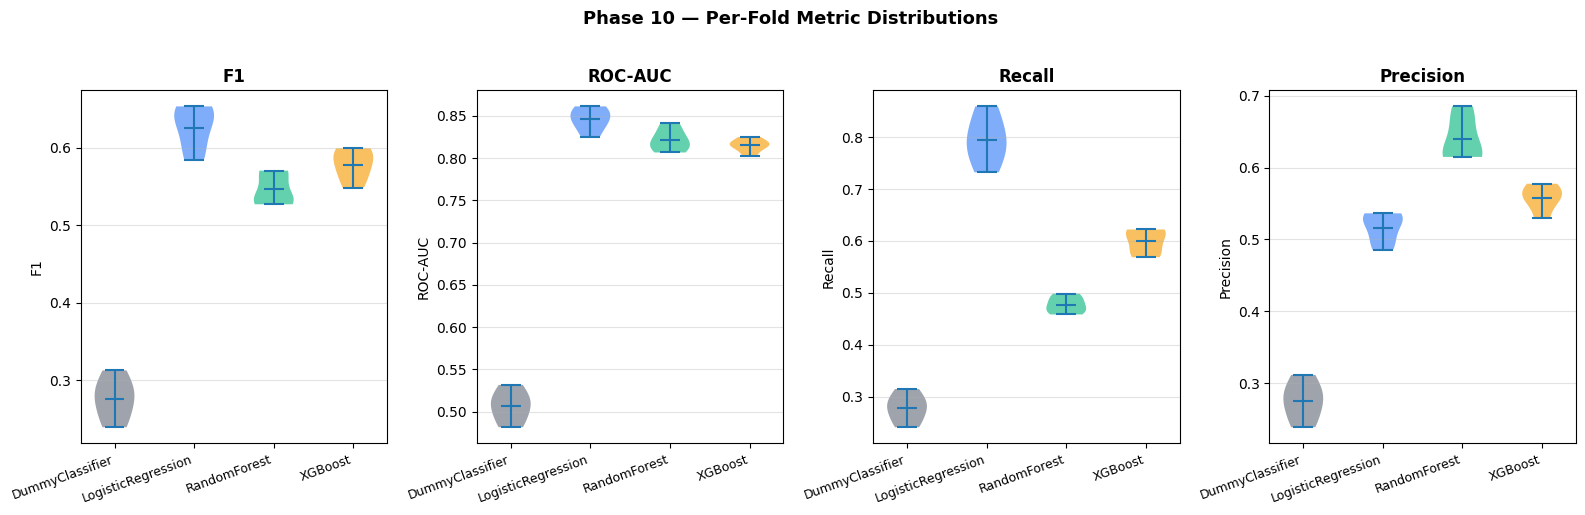

Saved: reports/cv_fold_distributions.png


In [8]:
with open('reports/baseline_cv_results.json') as f:
    p9 = json.load(f)
fold_results = p9['fold_results']

metrics = ['f1', 'roc_auc', 'recall', 'precision']
titles  = ['F1', 'ROC-AUC', 'Recall', 'Precision']

fig, axes = plt.subplots(1, 4, figsize=(16, 5))
for ax, metric, title in zip(axes, metrics, titles):
    data_plot = [[fd[metric] for fd in fold_results[n]] for n in MODEL_NAMES]
    parts = ax.violinplot(data_plot, showmeans=True, showmedians=False)
    for pc, name in zip(parts['bodies'], MODEL_NAMES):
        pc.set_facecolor(MODEL_COLORS[name])
        pc.set_alpha(0.65)
    ax.set_xticks(range(1, len(MODEL_NAMES)+1))
    ax.set_xticklabels(MODEL_NAMES, rotation=20, ha='right', fontsize=9)
    ax.set_title(title, fontsize=12, fontweight='bold')
    ax.set_ylabel(title, fontsize=10)
    ax.grid(axis='y', alpha=0.35)
plt.suptitle('Phase 10 — Per-Fold Metric Distributions',
             fontsize=13, fontweight='bold', y=1.02)
plt.tight_layout()
plt.savefig('reports/cv_fold_distributions.png', dpi=150, bbox_inches='tight')
plt.show()
print('Saved: reports/cv_fold_distributions.png')

## 10.6  Calibration Curves (Fold 5)

> A perfectly calibrated model's curve follows the diagonal.  
> Under the diagonal = overconfident; above = underconfident.

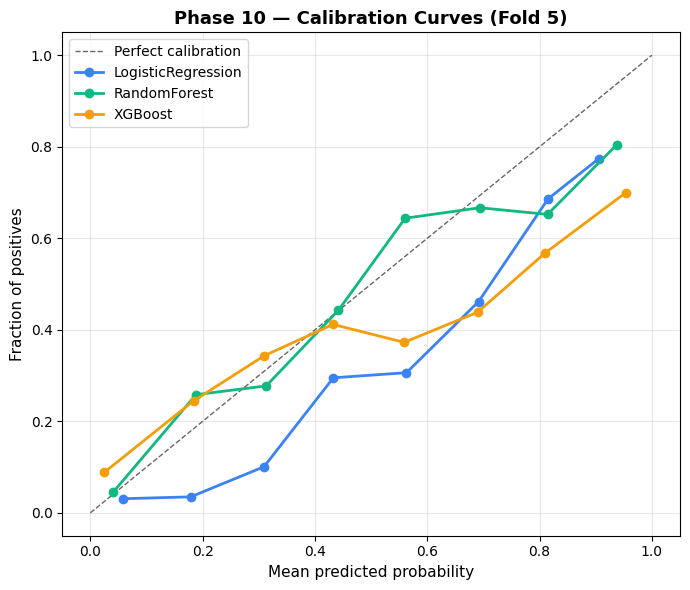

Saved: reports/cv_calibration_curves.png


In [9]:
last_fold = cv_folds[FOLD_NAMES[-1]]
X_tr  = X.iloc[last_fold['train_indices']].reset_index(drop=True)
y_tr  = y.iloc[last_fold['train_indices']].reset_index(drop=True)
X_val = X.iloc[last_fold['val_indices']].reset_index(drop=True)
y_val = y.iloc[last_fold['val_indices']].reset_index(drop=True)

cal_pipes = build_pipelines(y_tr)
for name, pipe in cal_pipes.items():
    if name == 'XGBoost':
        pipe.named_steps['model'].set_params(scale_pos_weight=_compute_spw(y_tr))
    pipe.fit(X_tr, y_tr)

fig, ax = plt.subplots(figsize=(7, 6))
ax.plot([0, 1], [0, 1], 'k--', lw=1, alpha=0.6, label='Perfect calibration')
for name in MODEL_NAMES:
    if name == 'DummyClassifier':
        continue
    try:
        y_prob = cal_pipes[name].predict_proba(X_val)[:, 1]
    except AttributeError:
        continue
    fp, mp = calibration_curve(y_val, y_prob, n_bins=8)
    ax.plot(mp, fp, 'o-', lw=2, color=MODEL_COLORS[name], label=name)
ax.set_xlabel('Mean predicted probability', fontsize=11)
ax.set_ylabel('Fraction of positives', fontsize=11)
ax.set_title('Phase 10 — Calibration Curves (Fold 5)',
             fontsize=13, fontweight='bold')
ax.legend(fontsize=10)
ax.grid(alpha=0.3)
plt.tight_layout()
plt.savefig('reports/cv_calibration_curves.png', dpi=150, bbox_inches='tight')
plt.show()
print('Saved: reports/cv_calibration_curves.png')

## 10.7  Decision Threshold Sensitivity (Fold 5)

> Default threshold is 0.50. Adjusting it trades Precision vs Recall.  
> Red dashed line = threshold that maximises F1 on the validation set.

In [10]:
import numpy as np
THRESHOLDS = [round(t, 2) for t in np.arange(0.10, 0.91, 0.05).tolist()]
ts_results = {}

for name in MODEL_NAMES:
    if name == 'DummyClassifier':
        continue
    try:
        y_prob = cal_pipes[name].predict_proba(X_val)[:, 1]
    except AttributeError:
        continue
    f1s, precs, recs = [], [], []
    for t in THRESHOLDS:
        y_pred_t = (y_prob >= t).astype(int)
        f1s.append(round(f1_score(y_val, y_pred_t, zero_division=0), 4))
        precs.append(round(precision_score(y_val, y_pred_t, zero_division=0), 4))
        recs.append(round(recall_score(y_val, y_pred_t, zero_division=0), 4))
    best_idx = int(np.argmax(f1s))
    ts_results[name] = {'thresholds': THRESHOLDS, 'f1': f1s,
                        'precision': precs, 'recall': recs}
    print(f'{name:<24} best_t={THRESHOLDS[best_idx]:.2f}  '
          f'F1={f1s[best_idx]:.4f}  Prec={precs[best_idx]:.4f}  '
          f'Rec={recs[best_idx]:.4f}')

LogisticRegression       best_t=0.60  F1=0.6452  Prec=0.5966  Rec=0.7023


RandomForest             best_t=0.35  F1=0.6334  Prec=0.5936  Rec=0.6789


XGBoost                  best_t=0.35  F1=0.6023  Prec=0.5291  Rec=0.6990


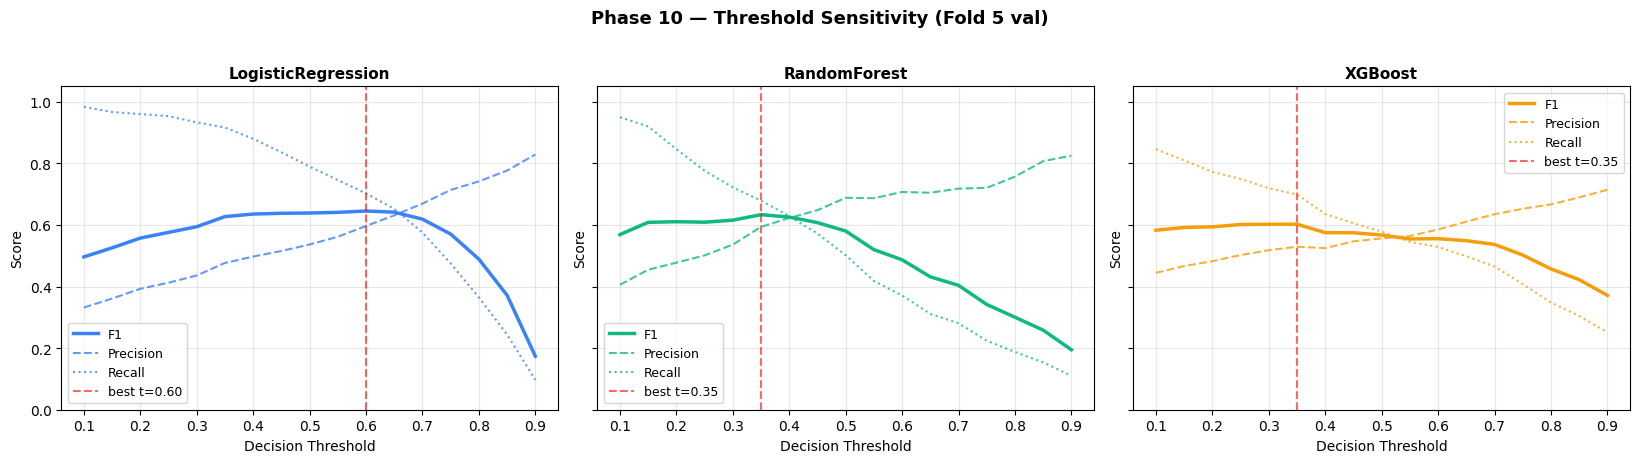

Saved: reports/cv_threshold_sensitivity.png


In [11]:
non_dummy = [n for n in MODEL_NAMES if n in ts_results]
fig, axes = plt.subplots(1, len(non_dummy),
                         figsize=(5.5*len(non_dummy), 4.5), sharey=True)
if len(non_dummy) == 1:
    axes = [axes]

for ax, name in zip(axes, non_dummy):
    d = ts_results[name]
    color = MODEL_COLORS[name]
    ax.plot(d['thresholds'], d['f1'],        color=color, lw=2.5, label='F1')
    ax.plot(d['thresholds'], d['precision'], color=color, lw=1.5,
            ls='--', alpha=0.8, label='Precision')
    ax.plot(d['thresholds'], d['recall'],    color=color, lw=1.5,
            ls=':', alpha=0.8, label='Recall')
    best_idx = int(np.argmax(d['f1']))
    ax.axvline(d['thresholds'][best_idx], color='red', ls='--', alpha=0.6,
               label=f"best t={d['thresholds'][best_idx]:.2f}")
    ax.set_title(name, fontsize=11, fontweight='bold')
    ax.set_xlabel('Decision Threshold', fontsize=10)
    ax.set_ylabel('Score', fontsize=10)
    ax.legend(fontsize=9)
    ax.grid(alpha=0.3)
    ax.set_ylim(0, 1.05)

plt.suptitle('Phase 10 — Threshold Sensitivity (Fold 5 val)',
             fontsize=13, fontweight='bold', y=1.02)
plt.tight_layout()
plt.savefig('reports/cv_threshold_sensitivity.png', dpi=150, bbox_inches='tight')
plt.show()
print('Saved: reports/cv_threshold_sensitivity.png')

## 10.8  Summary & Findings

In [12]:
print('\n' + '='*70)
print('PHASE 10 — CROSS-VALIDATION DEEP-DIVE  |  Summary')
print('='*70)

print(f"\n{'Model':<24} {'TrainF1':>9} {'ValF1':>9} {'Gap':>8}  Diagnosis")
print('-'*70)
for name, bv in bv_results.items():
    print(f"{name:<24} {bv['mean_train_f1']:>9.4f} {bv['mean_val_f1']:>9.4f} "
          f"{bv['gap']:>8.4f}  {bv['diagnosis']}")

print(f"\n{'Model':<24} {'BestThresh':>11} {'F1@best':>8} {'Prec':>8} {'Rec':>8}")
print('-'*70)
for name, d in ts_results.items():
    best_idx = int(np.argmax(d['f1']))
    print(f"{name:<24} {d['thresholds'][best_idx]:>11.2f} "
          f"{d['f1'][best_idx]:>8.4f} {d['precision'][best_idx]:>8.4f} "
          f"{d['recall'][best_idx]:>8.4f}")

print('\nNext: Phase 11 — Overfitting/Underfitting Diagnosis.')


PHASE 10 — CROSS-VALIDATION DEEP-DIVE  |  Summary

Model                      TrainF1     ValF1      Gap  Diagnosis
----------------------------------------------------------------------
DummyClassifier             0.2544    0.2762  -0.0218  underfitting
LogisticRegression          0.6326    0.6258   0.0067  good_fit
RandomForest                0.9958    0.5465   0.4494  overfitting
XGBoost                     0.9568    0.5780   0.3788  overfitting

Model                     BestThresh  F1@best     Prec      Rec
----------------------------------------------------------------------
LogisticRegression              0.60   0.6452   0.5966   0.7023
RandomForest                    0.35   0.6334   0.5936   0.6789
XGBoost                         0.35   0.6023   0.5291   0.6990

Next: Phase 11 — Overfitting/Underfitting Diagnosis.


## 10.9  Update PROGRESS.md

In [13]:
from datetime import date
prog_path = Path('PROGRESS.md')
content   = prog_path.read_text(encoding='utf-8')
old = '| 10    | Cross-Validation              | \u23f3 Pending  |            |'
new = f'| 10    | Cross-Validation              | \u2705 Complete | {date.today()} |'
if old in content:
    prog_path.write_text(content.replace(old, new), encoding='utf-8')
    print(f'PROGRESS.md updated: Phase 10 -> Complete ({date.today()})')
else:
    print('Pattern not found in PROGRESS.md — update manually.')

Pattern not found in PROGRESS.md — update manually.
